## Open Tools, Open Sky
### Doing LSST Science with Public Rubin Data & LINCC Frameworks
#### **Latest update**: Oct. 22 / 2026, Jorge I. Zuluaga

## Photometry example

This notebook follows the photometry analysis one step at a time.

1. Lomb–Scargle periodogram of one band.
2. Democratic vote of the three best-sampled bands.
3. Two-peak joint model of the voted periods. A voted period that lands on a campaign alias is marked and is not adopted.
4. Color indices of the adopted model.

Change `PROVID` in the asteroid cell and run the notebook again. Every period, frequency, and color below is computed from that asteroid. The steps are written out in the cells.

### Tools required

In [1]:
from pathlib import Path
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from astropy.timeseries import LombScargle, LombScargleMultiband
from IPython.display import Image, display
from scipy.signal import find_peaks

ROOT = Path.cwd()
if not (ROOT / "data" / "obs_sbn_X05_full_mpc_desig.parquet").exists():
    ROOT = ROOT / "code"
OBS_FILE = ROOT / "data" / "obs_sbn_X05_full_mpc_desig.parquet"
GEOM_FILE = ROOT / "data" / "obs_final_elements_geometry_H.parquet"

# Search window of the periodogram. Photometric periods, in hours.
# The rotation period is twice the photometric period.
PERIOD_MIN_H = 0.5 / 60.0
PERIOD_MAX_H = 24.0
N_FREQ = 100_000

# Vote: three best-sampled filters among g, r, i, z. u and y stay out.
VOTE_BANDS_EXCLUDED = ("Lu", "Ly")
VOTE_N_BANDS = 3
VOTE_MIN_POINTS = 5
AGREE_FRAC = 0.03
DAILY_ALIAS_TOL = 0.1  # cycles per day

# Joint model.
K_HARMONIC = 2
MERGE_TOL = 0.1  # cycles per day
ALIAS_P_MIN_H = 2.0  # shortest rotation period of a campaign alias

BAND_COLOR = {
    "g": "#12ffff", "r": "#00d200", "i": "#ffff12",
    "z": "#ff5252", "y": "#ff12ff", "u": "#5252ff",
}
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("observations:", OBS_FILE.name)
print("geometry:", GEOM_FILE.name)
print("figures:", FIG_DIR)

observations: obs_sbn_X05_full_mpc_desig.parquet
geometry: obs_final_elements_geometry_H.parquet
figures: /Users/jzuluaga/dev/MVROC/code/figures


### Asteroid

`PROVID` is the only asteroid-specific input. `EXAMPLE_BAND` is the filter used for the single-band periodogram. The vote still chooses its own three filters from the data.

In [102]:
# PROVID = "2025 ML17" # Asteroid with 38 h Lr periodogram
# PROVID = "2025 ME15" # A very good example with 2 periods
PROVID = "2025 ML35" # An example of aliases
EXAMPLE_BAND = "Lr"
ASTEROID = PROVID.replace(" ", "_")

### Prepare data

Read this asteroid from the observation table. Single-letter filter names are written as `Lg`, `Lr`, `Li`. The absolute magnitude *H* is taken from the geometry table at the same epoch. The time origin is the first row after sorting by filter and time, the same origin used for the whole analysis.

In [103]:
columns = ["obstime", "provid", "ra", "dec", "band", "mag", "rmsmag", "mpc_designation"]
df_obj = pq.read_table(OBS_FILE, columns=columns, filters=[("provid", "==", PROVID)]).to_pandas()
df_obj["band"] = df_obj["band"].apply(lambda b: f"L{b}" if pd.notnull(b) and len(str(b)) == 1 else b)
df_obj["obstime"] = pd.to_datetime(df_obj["obstime"])
df_obj[["ra", "dec", "mag", "rmsmag"]] = df_obj[["ra", "dec", "mag", "rmsmag"]].apply(pd.to_numeric, errors="coerce")

designations = []
if "mpc_designation" in df_obj.columns:
    values = df_obj["mpc_designation"].dropna().astype(str).str.strip()
    values = values[~values.str.lower().isin(["", "nan", "none"])]
    designations = values.unique().tolist()
frames = []
for designation in designations:
    table = pq.read_table(
        GEOM_FILE,
        columns=["obstime", "mag", "H"],
        filters=[("mpc_designation", "==", str(designation))],
    ).to_pandas()
    table["obstime"] = pd.to_datetime(table["obstime"])
    frames.append(table)
if frames:
    df_geom = pd.concat(frames, ignore_index=True).drop_duplicates("obstime")
else:
    df_geom = pd.DataFrame(columns=["obstime", "mag", "H"])
df_obj = pd.merge(df_obj, df_geom, on="obstime", how="left", suffixes=("", "_geom"))
df_obj = df_obj.sort_values(["band", "obstime"]).reset_index(drop=True)
t0_obs = df_obj["obstime"].iloc[0]
df_obj["t_days"] = (df_obj["obstime"] - t0_obs).dt.total_seconds() / 86400.0
print(f"{len(df_obj)} observations, {int(df_obj['H'].notna().sum())} with absolute magnitude H")
print("designations:", ", ".join(designations) if designations else "none")

459 observations, 459 with absolute magnitude H
designations: 2025 ML35


### Asteroid data

In [104]:
t_min = df_obj["obstime"].min()
t_max = df_obj["obstime"].max()
span_days = (t_max - t_min).total_seconds() / 86400.0
counts = df_obj["band"].value_counts()
print(f"From {t_min} to {t_max}")
print(f"Campaign duration T = {span_days:.2f} days")
print("Observations per band:")
print(counts.to_string())

From 2025-04-22 02:38:48.940000 to 2025-05-04 03:38:19.510000
Campaign duration T = 12.04 days
Observations per band:
band
Lr    202
Lg    133
Li    124


### Periodogram

The example band is searched on its own. The periodogram is the generalized Lomb–Scargle periodogram. A photometric frequency \(f\), in cycles per day, gives \(P_\mathrm{rot} = 48/f\) hours. Periods shorter than twice the median spacing of the points are excluded. The period reported here is the frequency of maximum power that survives that cut.

Lr: 202 points with H


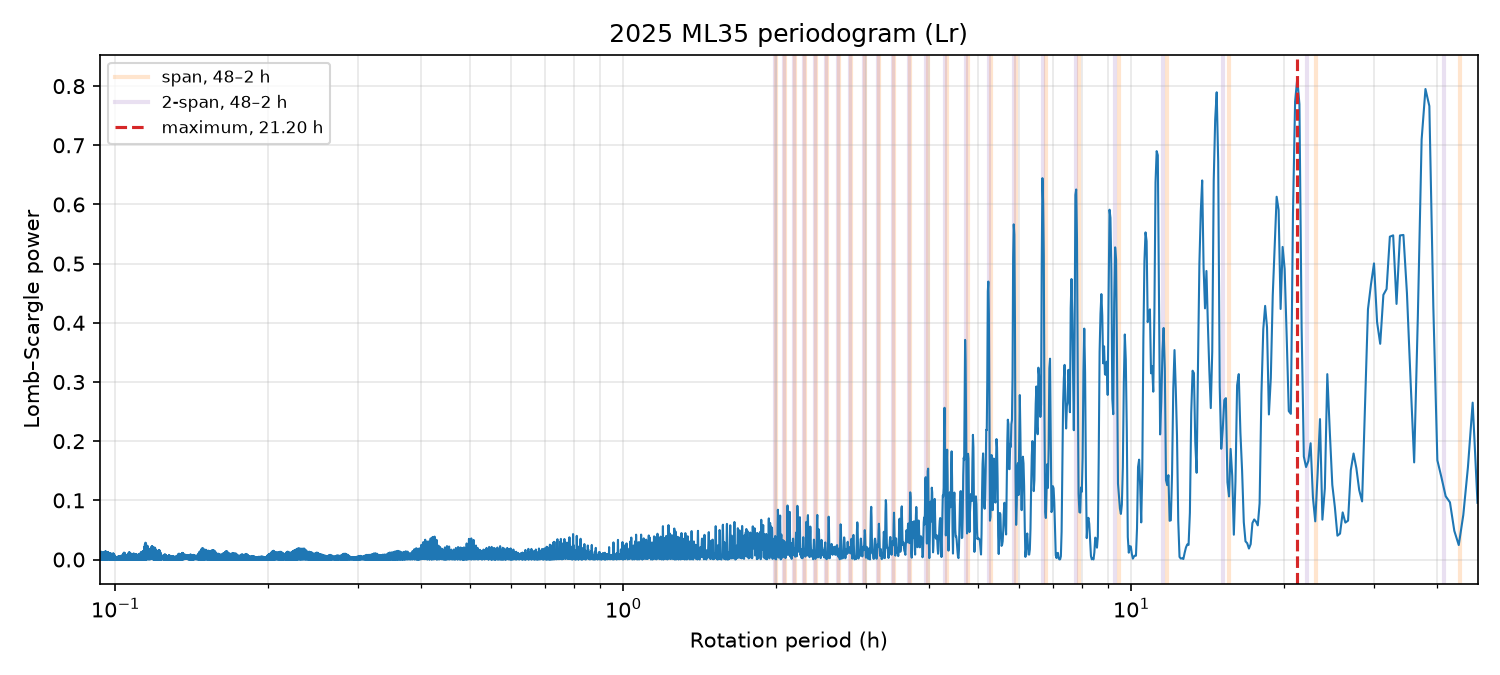

/Users/jzuluaga/dev/MVROC/code/figures/2025_ML35_periodogram.png
Maximum: P_rot = 21.20 h, P_phot = 10.60 h, power = 0.813
Cadence cut = 0.09 h (rotation)
Peaks at or above 80% of the maximum: 4


,frequency,rotational_period_h,relative_power
0,2.264,21.205,1.000
1,1.266,37.914,0.978
2,3.261,14.718,0.971
3,4.281,11.212,0.849


In [105]:
df_band = df_obj[(df_obj["band"] == EXAMPLE_BAND) & df_obj["H"].notna()].copy()
print(f"{EXAMPLE_BAND}: {len(df_band)} points with H")
if len(df_band) < 5:
    raise RuntimeError(f"{EXAMPLE_BAND} has fewer than 5 points. Choose another EXAMPLE_BAND.")

t_band = df_band["t_days"].to_numpy(float)
y_band = df_band["H"].to_numpy(float)
dy_band = df_band["rmsmag"].fillna(0.01).to_numpy(float)

# Frequency grid, in cycles per day. At least N_FREQ samples.
# A long arc is refined so a peak of width 1/T contains about five samples.
f_min = 24.0 / PERIOD_MAX_H
f_max = 24.0 / PERIOD_MIN_H
baseline_band = float(np.ptp(t_band))
n_freq = N_FREQ
if baseline_band > 0:
    n_freq = max(n_freq, int(np.ceil((f_max - f_min) * 5.0 * baseline_band)) + 1)
freq_grid_band = np.linspace(f_min, f_max, n_freq)

ls_band = LombScargle(t_band, y_band, dy_band)
power_band = np.asarray(ls_band.power(freq_grid_band), dtype=float)

# Cadence cut: twice the median spacing, as a photometric period in hours.
dt_hours = np.diff(np.sort(t_band)) * 24.0
dt_hours = dt_hours[dt_hours > 0]
cadence_phot_h = 2.0 * float(np.median(dt_hours)) if len(dt_hours) else 0.0
allowed = (24.0 / freq_grid_band) >= cadence_phot_h
if not np.any(allowed):
    allowed = np.ones(len(freq_grid_band), dtype=bool)
    cadence_phot_h = 0.0
i_max = int(np.flatnonzero(allowed)[np.argmax(power_band[allowed])])
f_band = float(freq_grid_band[i_max])
power_max = float(power_band[i_max])
p_rot_band = 48.0 / f_band
p_phot_band = 24.0 / f_band

# Peaks that reach 80% of the maximum and sit above the cadence cut.
peak_idx, _ = find_peaks(power_band)
high = np.intersect1d(peak_idx, np.where(power_band >= 0.8 * power_max)[0])
high = high[(24.0 / freq_grid_band[high]) >= cadence_phot_h]
rows = []
for idx in high:
    freq = float(freq_grid_band[idx])
    rows.append({
        "frequency": freq,
        "rotational_period_h": 48.0 / freq,
        "relative_power": float(power_band[idx] / power_max),
    })
if not rows:
    rows.append({"frequency": f_band, "rotational_period_h": p_rot_band, "relative_power": 1.0})
df_peaks = pd.DataFrame(rows).sort_values("relative_power", ascending=False).reset_index(drop=True)

period_h = 48.0 / freq_grid_band
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(period_h, power_band, color="C0", lw=1.0)
t_campaign = df_obj["t_days"].to_numpy(float)
t_campaign = t_campaign[np.isfinite(t_campaign)]
span_campaign = float(np.ptp(t_campaign)) if len(t_campaign) else 0.0
if span_campaign > 0:
    # f = 1/T + k and 2/T + k. P_rot = 48/f, from the 48 h edge down to 2 h.
    f_long = 48.0 / (2.0 * PERIOD_MAX_H)
    f_short = 48.0 / ALIAS_P_MIN_H
    k_alias_min = int(np.ceil(f_long - 2.0 / span_campaign - 1e-12))
    k_alias_max = int(np.ceil(f_short - 1.0 / span_campaign - 1e-12))
    for k in range(k_alias_min, k_alias_max + 1):
        for base, name, color in (
            (1.0 / span_campaign, "span", "C1"),
            (2.0 / span_campaign, "2-span", "C4"),
        ):
            freq = base + float(k)
            if freq <= 0:
                continue
            ax.axvline(
                48.0 / freq,
                color=color,
                ls="-",
                lw=2,
                alpha=0.2,
                zorder=1,
                label=(
                    f"{name}, {2.0 * PERIOD_MAX_H:.0f}–{ALIAS_P_MIN_H:.0f} h"
                    if k == k_alias_min else None
                ),
            )
ax.axvline(p_rot_band, color="C3", ls="--", lw=1.5, label=f"maximum, {p_rot_band:.2f} h")
ax.set_xscale("log")
ax.set_xlim(max(2.0 * cadence_phot_h, 2.0 * PERIOD_MIN_H), 2.0 * PERIOD_MAX_H)
ax.set_xlabel("Rotation period (h)")
ax.set_ylabel("Lomb–Scargle power")
ax.set_title(f"{PROVID} periodogram ({EXAMPLE_BAND})")
ax.legend(loc="upper left", fontsize=8)
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
periodogram_path = FIG_DIR / f"{ASTEROID}_periodogram.png"
fig.savefig(periodogram_path, dpi=150)
plt.close(fig)
display(Image(filename=str(periodogram_path)))
print(periodogram_path)

print(f"Maximum: P_rot = {p_rot_band:.2f} h, P_phot = {p_phot_band:.2f} h, power = {power_max:.3f}")
print(f"Cadence cut = {2.0 * cadence_phot_h:.2f} h (rotation)")
print(f"Peaks at or above 80% of the maximum: {len(df_peaks)}")
display(df_peaks.round(3))

### Democratic vote

The three filters with the most points, among \(g\), \(r\), \(i\), and \(z\), each vote with their own periodogram. Every pair votes, and the three together vote. A pair or a triplet uses the multiband periodogram, with one mean per filter and a shared frequency. All of these series use one frequency grid, built from their combined times.

Two periods count as the same vote when they agree to 3%, or when their photometric frequencies differ by \(1 \pm 0.1\) or \(2 \pm 0.1\) cycles per day. An alias is kept in the count. The largest group wins. If the vote is unanimous, the period comes from the series that combines the most filters. Otherwise it comes from the single filter, inside the winning group, that has the most points.

In [106]:
usable = (
    df_obj.dropna(subset=["H"])
    .loc[~df_obj["band"].isin(VOTE_BANDS_EXCLUDED), "band"]
    .value_counts()
)
usable = usable[usable >= VOTE_MIN_POINTS].head(VOTE_N_BANDS)
print("Filters in the vote:")
print(usable.to_string())
if usable.empty:
    raise RuntimeError("No filter has enough points to vote.")

pieces = [df_obj[(df_obj["band"] == band) & df_obj["H"].notna()] for band in usable.index]
df_top = pd.concat(pieces, ignore_index=True)
t_top = df_top["t_days"].to_numpy(float)
baseline_vote = float(np.ptp(t_top))
n_freq_vote = N_FREQ
if baseline_vote > 0:
    n_freq_vote = max(n_freq_vote, int(np.ceil((f_max - f_min) * 5.0 * baseline_vote)) + 1)
freq_grid = np.linspace(f_min, f_max, n_freq_vote)
print(f"Shared grid: {len(freq_grid)} frequencies")

series = []
for band, n_points in usable.items():
    df_i = df_obj[(df_obj["band"] == band) & df_obj["H"].notna()]
    t = df_i["t_days"].to_numpy(float)
    y = df_i["H"].to_numpy(float)
    dy = np.maximum(df_i["rmsmag"].fillna(0.01).to_numpy(float), 1e-4)
    power = np.asarray(LombScargle(t, y, dy).power(freq_grid), dtype=float)
    dt = np.diff(np.sort(t)) * 24.0
    dt = dt[dt > 0]
    cut = 2.0 * float(np.median(dt)) if len(dt) else 0.0
    keep = (24.0 / freq_grid) >= cut if cut > 0 else np.ones(len(freq_grid), dtype=bool)
    if not np.any(keep):
        keep = np.ones(len(freq_grid), dtype=bool)
    best = int(np.flatnonzero(keep)[np.argmax(power[keep])])
    freq = float(freq_grid[best])
    found = {
        "label": str(band),
        "n": int(n_points),
        "freq": freq,
        "p_rot_h": 48.0 / freq,
        "power": float(power[best]),
    }
    series.append(found)
    print(f"  {found['label']}: N = {found['n']}, P_rot = {found['p_rot_h']:.2f} h, power = {found['power']:.3f}")

bands = [str(band) for band in usable.index]
combos = [[bands[i], bands[j]] for i in range(len(bands)) for j in range(i + 1, len(bands))]
if len(bands) > 2:
    combos.append(list(bands))
for combo in combos:
    df_i = df_obj[df_obj["band"].isin(combo) & df_obj["H"].notna()]
    t = df_i["t_days"].to_numpy(float)
    y = df_i["H"].to_numpy(float)
    dy = np.maximum(df_i["rmsmag"].fillna(0.01).to_numpy(float), 1e-4)
    labels = df_i["band"].to_numpy()
    power = np.asarray(LombScargleMultiband(t, y, labels, dy).power(freq_grid), dtype=float)
    dt = np.diff(np.sort(t)) * 24.0
    dt = dt[dt > 0]
    cut = 2.0 * float(np.median(dt)) if len(dt) else 0.0
    keep = (24.0 / freq_grid) >= cut if cut > 0 else np.ones(len(freq_grid), dtype=bool)
    if not np.any(keep):
        keep = np.ones(len(freq_grid), dtype=bool)
    best = int(np.flatnonzero(keep)[np.argmax(power[keep])])
    freq = float(freq_grid[best])
    found = {
        "label": "+".join(combo),
        "n": int(len(df_i)),
        "freq": freq,
        "p_rot_h": 48.0 / freq,
        "power": float(power[best]),
    }
    series.append(found)
    print(f"  {found['label']}: N = {found['n']}, P_rot = {found['p_rot_h']:.2f} h, power = {found['power']:.3f}")

# Periods that agree, or that differ by one or two cycles per day, share a group.
parent = list(range(len(series)))
for i in range(len(series)):
    for j in range(i + 1, len(series)):
        p1 = series[i]["p_rot_h"]
        p2 = series[j]["p_rot_h"]
        agree = abs(p1 - p2) <= AGREE_FRAC * max(p1, p2)
        separation = abs(48.0 / p1 - 48.0 / p2)
        daily = abs(separation - 1.0) <= DAILY_ALIAS_TOL or abs(separation - 2.0) <= DAILY_ALIAS_TOL
        if not (agree or daily):
            continue
        a, b = i, j
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        while parent[b] != b:
            parent[b] = parent[parent[b]]
            b = parent[b]
        parent[a] = b

groups = {}
for i in range(len(series)):
    a = i
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    groups.setdefault(a, []).append(i)
winner_ids = max(groups.values(), key=lambda members: (len(members), -min(members)))
single_ids = [i for i in winner_ids if "+" not in series[i]["label"]]
combined_ids = [i for i in winner_ids if "+" in series[i]["label"]]
unanimous = len(winner_ids) == len(series)
if unanimous and combined_ids:
    chosen = max(combined_ids, key=lambda i: series[i]["label"].count("+"))
elif single_ids:
    chosen = max(single_ids, key=lambda i: series[i]["n"])
else:
    chosen = winner_ids[0]
p_adopted_vote = float(series[chosen]["p_rot_h"])
vote_labels = [series[i]["label"] for i in winner_ids]
print(
    f"Adopted by the vote: {p_adopted_vote:.4f} h from {series[chosen]['label']}, "
    f"{len(winner_ids)}/{len(series)} votes ({', '.join(vote_labels)})"
)

vote = pd.DataFrame(series)
vote["f_per_day"] = 48.0 / vote["p_rot_h"]
display(vote.round(3))

# The example band on its own grid, and the same band on the shared vote grid.
same_band = vote.loc[vote["label"] == EXAMPLE_BAND]
if len(same_band):
    p_vote_band = float(same_band["p_rot_h"].iloc[0])
    print(f"{EXAMPLE_BAND} alone: {p_rot_band:.2f} h. {EXAMPLE_BAND} on the shared grid: {p_vote_band:.2f} h.")

# The two largest groups, and whether they are one or two cycles per day apart.
ranked_groups = sorted(groups.values(), key=lambda members: (len(members), -min(members)), reverse=True)
if len(ranked_groups) >= 2:
    second_ids = ranked_groups[1]
    second_single = [i for i in second_ids if "+" not in series[i]["label"]]
    second = max(second_single, key=lambda i: series[i]["n"]) if second_single else second_ids[0]
    p_second = float(series[second]["p_rot_h"])
    f_first = 48.0 / p_adopted_vote
    f_second = 48.0 / p_second
    separation = abs(f_first - f_second)
    print(f"Winning period {p_adopted_vote:.2f} h, f = {f_first:.3f} d^-1")
    print(f"Next group {p_second:.2f} h ({series[second]['label']}), f = {f_second:.3f} d^-1")
    print(f"|f difference| = {separation:.3f} d^-1")
    if abs(separation - 1.0) <= DAILY_ALIAS_TOL or abs(separation - 2.0) <= DAILY_ALIAS_TOL:
        print("The two groups are one or two cycles per day apart, so they would share a vote.")
    else:
        print("The two groups are not one or two cycles per day apart, so they stay separate.")
else:
    print("Every series landed in the same group.")

Filters in the vote:
band
Lr    202
Lg    133
Li    124
Shared grid: 173336 frequencies
  Lr: N = 202, P_rot = 21.22 h, power = 0.815
  Lg: N = 133, P_rot = 14.73 h, power = 0.699
  Li: N = 124, P_rot = 20.76 h, power = 0.824
  Lr+Lg: N = 335, P_rot = 21.22 h, power = 0.771
  Lr+Li: N = 326, P_rot = 21.37 h, power = 0.794
  Lg+Li: N = 257, P_rot = 14.73 h, power = 0.749
  Lr+Lg+Li: N = 459, P_rot = 14.73 h, power = 0.772
Adopted by the vote: 14.7290 h from Lr+Lg+Li, 7/7 votes (Lr, Lg, Li, Lr+Lg, Lr+Li, Lg+Li, Lr+Lg+Li)


,label,n,freq,p_rot_h,power,f_per_day
0,Lr,202,2.262,21.217,0.815,2.262
1,Lg,133,3.259,14.729,0.699,3.259
2,Li,124,2.312,20.760,0.824,2.312
3,Lr+Lg,335,2.262,21.217,0.771,2.262
4,Lr+Li,326,2.246,21.374,0.794,2.246
5,Lg+Li,257,3.259,14.729,0.749,3.259
6,Lr+Lg+Li,459,3.259,14.729,0.772,3.259


Lr alone: 21.20 h. Lr on the shared grid: 21.22 h.
Every series landed in the same group.


### The voted period on the example-band periodogram

The adopted period is marked on the periodogram of the example band. Its relative power is read from that periodogram, at the peak that agrees with the voted period.

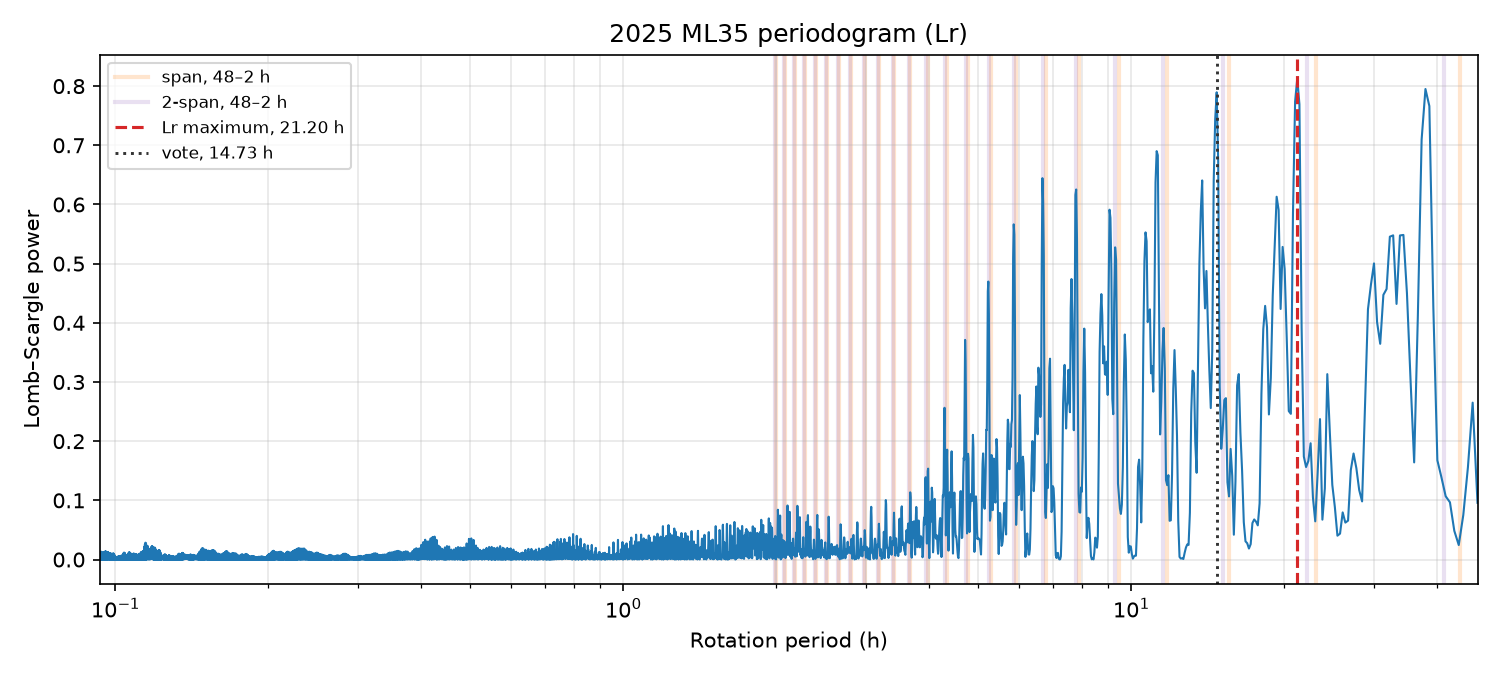

/Users/jzuluaga/dev/MVROC/code/figures/2025_ML35_periodogram.png
On the Lr periodogram the voted period sits on the peak at 14.72 h, with relative power 0.971.


In [107]:
f_adopted_vote = 48.0 / p_adopted_vote
close = df_peaks.loc[(df_peaks["rotational_period_h"] - p_adopted_vote).abs() <= AGREE_FRAC * p_adopted_vote]
i_near = int(np.argmin(np.abs(freq_grid_band - f_adopted_vote)))
power_at_vote = float(power_band[i_near] / power_max)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(period_h, power_band, color="C0", lw=1.0)
if span_campaign > 0:
    f_long = 48.0 / (2.0 * PERIOD_MAX_H)
    f_short = 48.0 / ALIAS_P_MIN_H
    k_alias_min = int(np.ceil(f_long - 2.0 / span_campaign - 1e-12))
    k_alias_max = int(np.ceil(f_short - 1.0 / span_campaign - 1e-12))
    for k in range(k_alias_min, k_alias_max + 1):
        for base, name, color in (
            (1.0 / span_campaign, "span", "C1"),
            (2.0 / span_campaign, "2-span", "C4"),
        ):
            freq = base + float(k)
            if freq <= 0:
                continue
            ax.axvline(
                48.0 / freq,
                color=color,
                ls="-",
                lw=2,
                alpha=0.2,
                zorder=1,
                label=(
                    f"{name}, {2.0 * PERIOD_MAX_H:.0f}–{ALIAS_P_MIN_H:.0f} h"
                    if k == k_alias_min else None
                ),
            )
ax.axvline(p_rot_band, color="C3", ls="--", lw=1.5, label=f"{EXAMPLE_BAND} maximum, {p_rot_band:.2f} h")
ax.axvline(p_adopted_vote, color="0.2", ls=":", lw=1.4, label=f"vote, {p_adopted_vote:.2f} h")
ax.set_xscale("log")
ax.set_xlim(max(2.0 * cadence_phot_h, 2.0 * PERIOD_MIN_H), 2.0 * PERIOD_MAX_H)
ax.set_xlabel("Rotation period (h)")
ax.set_ylabel("Lomb–Scargle power")
ax.set_title(f"{PROVID} periodogram ({EXAMPLE_BAND})")
ax.legend(loc="upper left", fontsize=8)
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
periodogram_path = FIG_DIR / f"{ASTEROID}_periodogram.png"
fig.savefig(periodogram_path, dpi=150)
plt.close(fig)
display(Image(filename=str(periodogram_path)))
print(periodogram_path)

if len(close):
    hit = close.sort_values("relative_power", ascending=False).iloc[0]
    print(
        f"On the {EXAMPLE_BAND} periodogram the voted period sits on the peak at "
        f"{hit['rotational_period_h']:.2f} h, with relative power {hit['relative_power']:.3f}."
    )
else:
    print(
        f"The voted period is not one of the peaks above 80% of the {EXAMPLE_BAND} maximum. "
        f"The power at that frequency is {power_at_vote:.3f} of the maximum."
    )

### Two-peak comparison

Each period returned by the democratic vote is fitted with one harmonic model of order 2. Filters \(g\), \(r\), \(i\), \(z\), and \(y\) share the curve and keep a zero point each. The filter \(u\) stays out of this fit. The reference filter is \(r\) when \(r\) has data.

A voted frequency is a campaign alias when it lies within 0.1 cycles per day of \(1/T+k\) or \(2/T+k\). The integer \(k\) runs from the 48 h edge of the search down to a rotation period of 2 h. The chi-squared is computed only for the voted frequencies. The other aliases stay on the periodogram and are not fitted.

Before the fit, each filter is clipped to its own magnitude interval: the 5th to 95th percentile, widened by \(\max(0.2,\ 0.35\,(P_{95}-P_5))\). The same points are used for every candidate.

The adopted period is the lowest reduced chi-squared among the two-peak models that are not campaign aliases. A voted period that is an alias is printed with its chi-squared and is not adopted. If every two-peak model is an alias, no rotation period is adopted.

In [108]:
alias = {"Lg": "g", "Lr": "r", "Li": "i", "Lz": "z", "Ly": "y", "Lu": "u"}
filt_order = ["g", "r", "i", "z", "y"]
df_fit = df_obj.dropna(subset=["H", "band"]).copy()
df_fit["filt"] = df_fit["band"].map(lambda b: alias.get(b, b))
rms = pd.to_numeric(df_fit["rmsmag"], errors="coerce").to_numpy(float)
df_fit["rmsmag"] = np.where(np.isfinite(rms) & (rms > 0), rms, 0.01)
df_fit = df_fit[df_fit["filt"].isin(filt_order)]

kept = []
n_rejected = 0
for filt_name, part in df_fit.groupby("filt", sort=False):
    values = part["H"].to_numpy(float)
    good = np.isfinite(values)
    if int(good.sum()) >= 8:
        for _ in range(5):
            sample = values[good]
            low, high = np.percentile(sample, [5, 95])
            margin = max(0.2, 0.35 * float(high - low))
            updated = np.isfinite(values) & (values >= low - margin) & (values <= high + margin)
            if int(updated.sum()) < 8 or np.array_equal(updated, good):
                break
            good = updated
    n_rejected += int((~good).sum())
    kept.append(part.loc[good])
df_fit = pd.concat(kept, ignore_index=True)
print(f"Rejected {n_rejected} magnitude outlier(s). {len(df_fit)} points remain.")

present = [f for f in filt_order if (df_fit["filt"] == f).any()]
print("Filters in the fit:", ", ".join(present))
if len(present) < 2:
    raise RuntimeError("The joint model needs at least two filters.")
if "r" in present:
    ref = "r"
else:
    ref = max(present, key=lambda f: int((df_fit["filt"] == f).sum()))
print(f"Reference filter: {ref}")

t_fit = df_fit["t_days"].to_numpy(float)
y_fit = df_fit["H"].to_numpy(float)
s_fit = np.maximum(df_fit["rmsmag"].to_numpy(float), 1e-4)
f_fit = df_fit["filt"].to_numpy()
t0_fit = float(np.min(t_fit))
span_fit = float(np.ptp(t_fit))
dt_fit = np.diff(np.sort(t_fit)) * 24.0
dt_fit = dt_fit[dt_fit > 0]
cadence_fit_h = 2.0 * float(np.median(dt_fit)) if len(dt_fit) else 0.0

# Voted frequencies first, so a merge keeps the frequency a series voted for.
merged = []
for item in series:
    freq = float(item["freq"])
    for group in merged:
        if abs(group["freq"] - freq) <= MERGE_TOL:
            if item["label"] not in group["labels"]:
                group["labels"].append(item["label"])
            break
    else:
        merged.append({"freq": freq, "labels": [item["label"]]})

# A voted frequency is a campaign alias when it lies within MERGE_TOL of
# f = 1/T + k or f = 2/T + k. k runs from the 48 h edge down to ALIAS_P_MIN_H.
# The chi-squared fit uses only the voted frequencies.
f_long = 48.0 / (2.0 * PERIOD_MAX_H)
f_short = 48.0 / ALIAS_P_MIN_H
k_alias_min = int(np.ceil(f_long - 2.0 / span_fit - 1e-12))
k_alias_max = int(np.ceil(f_short - 1.0 / span_fit - 1e-12))
print(f"Campaign aliases checked against the vote: T = {span_fit:.2f} d, k = {k_alias_min} to {k_alias_max}")
for group in merged:
    freq = float(group["freq"])
    for base, tag in ((1.0 / span_fit, "span"), (2.0 / span_fit, "2-span")):
        for k in range(k_alias_min, k_alias_max + 1):
            alias_freq = base + float(k)
            if alias_freq < f_min or alias_freq > f_max:
                continue
            if cadence_fit_h > 0 and (24.0 / alias_freq) < cadence_fit_h:
                continue
            if abs(freq - alias_freq) > MERGE_TOL:
                continue
            label = f"{tag} k={k:+d}"
            if label not in group["labels"]:
                group["labels"].append(label)

n_alias = sum(any(str(lab).startswith(("span", "2-span")) for lab in group["labels"]) for group in merged)
print(f"{len(merged)} voted periods, {n_alias} of them land on a campaign alias")

ls_power = LombScargleMultiband(t_fit, y_fit, f_fit, s_fit)
scored = []
for cand in merged:
    freq = float(cand["freq"])
    f_rot = freq / 2.0
    ph = 2.0 * np.pi * f_rot * t_fit
    cols = []
    names = []
    for filt in present:
        if filt == ref:
            continue
        cols.append((f_fit == filt).astype(float))
        names.append(f"c_{filt}")
    cols.append(np.ones(len(t_fit)))
    names.append("m_ref")
    for k in range(1, K_HARMONIC + 1):
        cols.append(np.sin(k * ph))
        cols.append(np.cos(k * ph))
        names.extend([f"sin{k}", f"cos{k}"])
    X = np.column_stack(cols)
    beta, *_ = np.linalg.lstsq(X / s_fit[:, None], y_fit / s_fit, rcond=None)
    resid = y_fit - X @ beta
    chi2 = float(np.sum((resid / s_fit) ** 2))
    chi2_nu = chi2 / max(len(y_fit) - X.shape[1], 1)

    phase_grid = np.linspace(0, 1, 400, endpoint=False)
    t_grid = t0_fit + phase_grid / f_rot
    ph_g = 2.0 * np.pi * f_rot * t_grid
    cols_g = [np.zeros(len(phase_grid)) for filt in present if filt != ref]
    cols_g.append(np.ones(len(phase_grid)))
    for k in range(1, K_HARMONIC + 1):
        cols_g.append(np.sin(k * ph_g))
        cols_g.append(np.cos(k * ph_g))
    y_model = np.column_stack(cols_g) @ beta

    offset = {ref: 0.0}
    for name, value in zip(names, beta):
        if name.startswith("c_"):
            offset[name[2:]] = float(value)
    y_on_ref = y_fit - np.array([offset.get(f, 0.0) for f in f_fit])

    cols_d = [np.zeros(len(t_fit)) for filt in present if filt != ref]
    cols_d.append(np.ones(len(t_fit)))
    for k in range(1, K_HARMONIC + 1):
        cols_d.append(np.sin(k * ph))
        cols_d.append(np.cos(k * ph))
    y_curve = np.column_stack(cols_d) @ beta

    span_model = float(np.ptp(y_model))
    if span_model < 0.01 or not np.isfinite(span_model):
        n_peaks = 0
    else:
        wrapped = np.concatenate([y_model, y_model, y_model])
        prominence = max(0.02, 0.15 * span_model)
        idx, _ = find_peaks(-wrapped, prominence=prominence)
        n_model = len(y_model)
        n_peaks = int(np.sum((idx >= n_model) & (idx < 2 * n_model)))

    distance = np.abs(y_on_ref - y_curve)
    n_drop = int(np.floor(0.10 * len(distance)))
    keep = np.argsort(distance)[: max(len(distance) - n_drop, 1)]
    scatter = float(np.mean(np.sqrt(distance[keep] ** 2 + s_fit[keep] ** 2)))
    amp = span_model
    amp_ratio = amp / scatter if scatter > 0 else np.nan
    power = float(np.asarray(ls_power.power([freq]), dtype=float).ravel()[0])
    cov = np.linalg.pinv((X / s_fit[:, None]).T @ (X / s_fit[:, None]))
    span_alias = int(any(str(lab).startswith(("span", "2-span")) for lab in cand["labels"]))
    scored.append({
        "freq": freq,
        "f_rot": f_rot,
        "p_rot_h": 48.0 / freq,
        "labels": list(cand["labels"]),
        "chi2_nu": chi2_nu,
        "n_peaks": n_peaks,
        "power": power,
        "amp": amp,
        "amp_ratio": amp_ratio,
        "span_alias": span_alias,
        "beta": beta,
        "names": names,
        "cov": cov,
        "offset": offset,
        "y_model": y_model,
        "y_on_ref": y_on_ref,
        "phase_grid": phase_grid,
    })

scored.sort(key=lambda item: (item["chi2_nu"], item["p_rot_h"]))
two_peaks = [item for item in scored if item["n_peaks"] == 2]
# A campaign alias can arrange the nights into a curve, so it is not adopted.
rotations = [item for item in two_peaks if not item["span_alias"]]
adopted = bool(rotations)
best = rotations[0] if adopted else (two_peaks[0] if two_peaks else None)
for item in scored:
    if item is best and adopted:
        mark = " selected"
    elif item is best:
        mark = " best fit, not a rotation period"
    else:
        mark = ""
    alias_mark = ", baseline alias" if item["span_alias"] else ""
    print(
        f"  {item['p_rot_h']:.4f} h ({', '.join(item['labels'])}): "
        f"chi2_nu = {item['chi2_nu']:.2f}, peaks = {item['n_peaks']}, "
        f"power = {item['power']:.3f}, A = {item['amp']:.3f}, A/s = {item['amp_ratio']:.3f}"
        f"{alias_mark}{mark}"
    )
if best is None:
    raise RuntimeError("No candidate has two brightness maxima.")
if adopted:
    print(
        f"Adopted: P_rot = {best['p_rot_h']:.4f} h, chi2_nu = {best['chi2_nu']:.2f}, "
        f"peaks = {best['n_peaks']}, power = {best['power']:.3f}, "
        f"A = {best['amp']:.3f}, A/s = {best['amp_ratio']:.3f}, "
        f"baseline alias = {best['span_alias']}"
    )
else:
    print(
        "No rotation period is adopted: every two-peak model is a campaign alias. "
        f"The best fit is {best['p_rot_h']:.4f} h, chi2_nu = {best['chi2_nu']:.2f}, "
        "and it is not a rotation period. The catalogue leaves this asteroid out."
    )

# A voted period that also lands on a campaign alias.
for item in scored:
    voted = any(not str(lab).startswith(("span", "2-span")) for lab in item["labels"])
    if not item["span_alias"] or not voted:
        continue
    for lab in item["labels"]:
        text = str(lab)
        if text.startswith("2-span k="):
            base = 2.0 / span_fit
            k = int(text.replace("2-span k=", ""))
        elif text.startswith("span k="):
            base = 1.0 / span_fit
            k = int(text.replace("span k=", ""))
        else:
            continue
        f_alias = base + k
        print(
            f"{item['p_rot_h']:.2f} h has f = {item['freq']:.3f} d^-1. "
            f"{text}: {base:.3f} + ({k:+d}) = {f_alias:.3f} d^-1. "
            f"Difference = {item['freq'] - f_alias:.3f} d^-1."
        )

Rejected 0 magnitude outlier(s). 459 points remain.
Filters in the fit: g, r, i
Reference filter: r
Campaign aliases checked against the vote: T = 12.04 d, k = 1 to 24
2 voted periods, 2 of them land on a campaign alias
  21.2172 h (Lr, Li, Lr+Lg, Lr+Li, 2-span k=+2): chi2_nu = 1.19, peaks = 2, power = 0.765, A = 0.850, A/s = 5.778, baseline alias best fit, not a rotation period
  14.7290 h (Lg, Lg+Li, Lr+Lg+Li, 2-span k=+3): chi2_nu = 1.30, peaks = 2, power = 0.772, A = 0.729, A/s = 4.884, baseline alias
No rotation period is adopted: every two-peak model is a campaign alias. The best fit is 21.2172 h, chi2_nu = 1.19, and it is not a rotation period. The catalogue leaves this asteroid out.
21.22 h has f = 2.262 d^-1. 2-span k=+2: 0.166 + (+2) = 2.166 d^-1. Difference = 0.096 d^-1.
14.73 h has f = 3.259 d^-1. 2-span k=+3: 0.166 + (+3) = 3.166 d^-1. Difference = 0.093 d^-1.


The adopted model is the wide panel. Other voted periods that also have two maxima are drawn below it. A red title means the period is an alias of the campaign duration. The dotted lines on the adopted panel are the 2.5th and 97.5th percentiles of the photometry, shifted onto the reference filter.

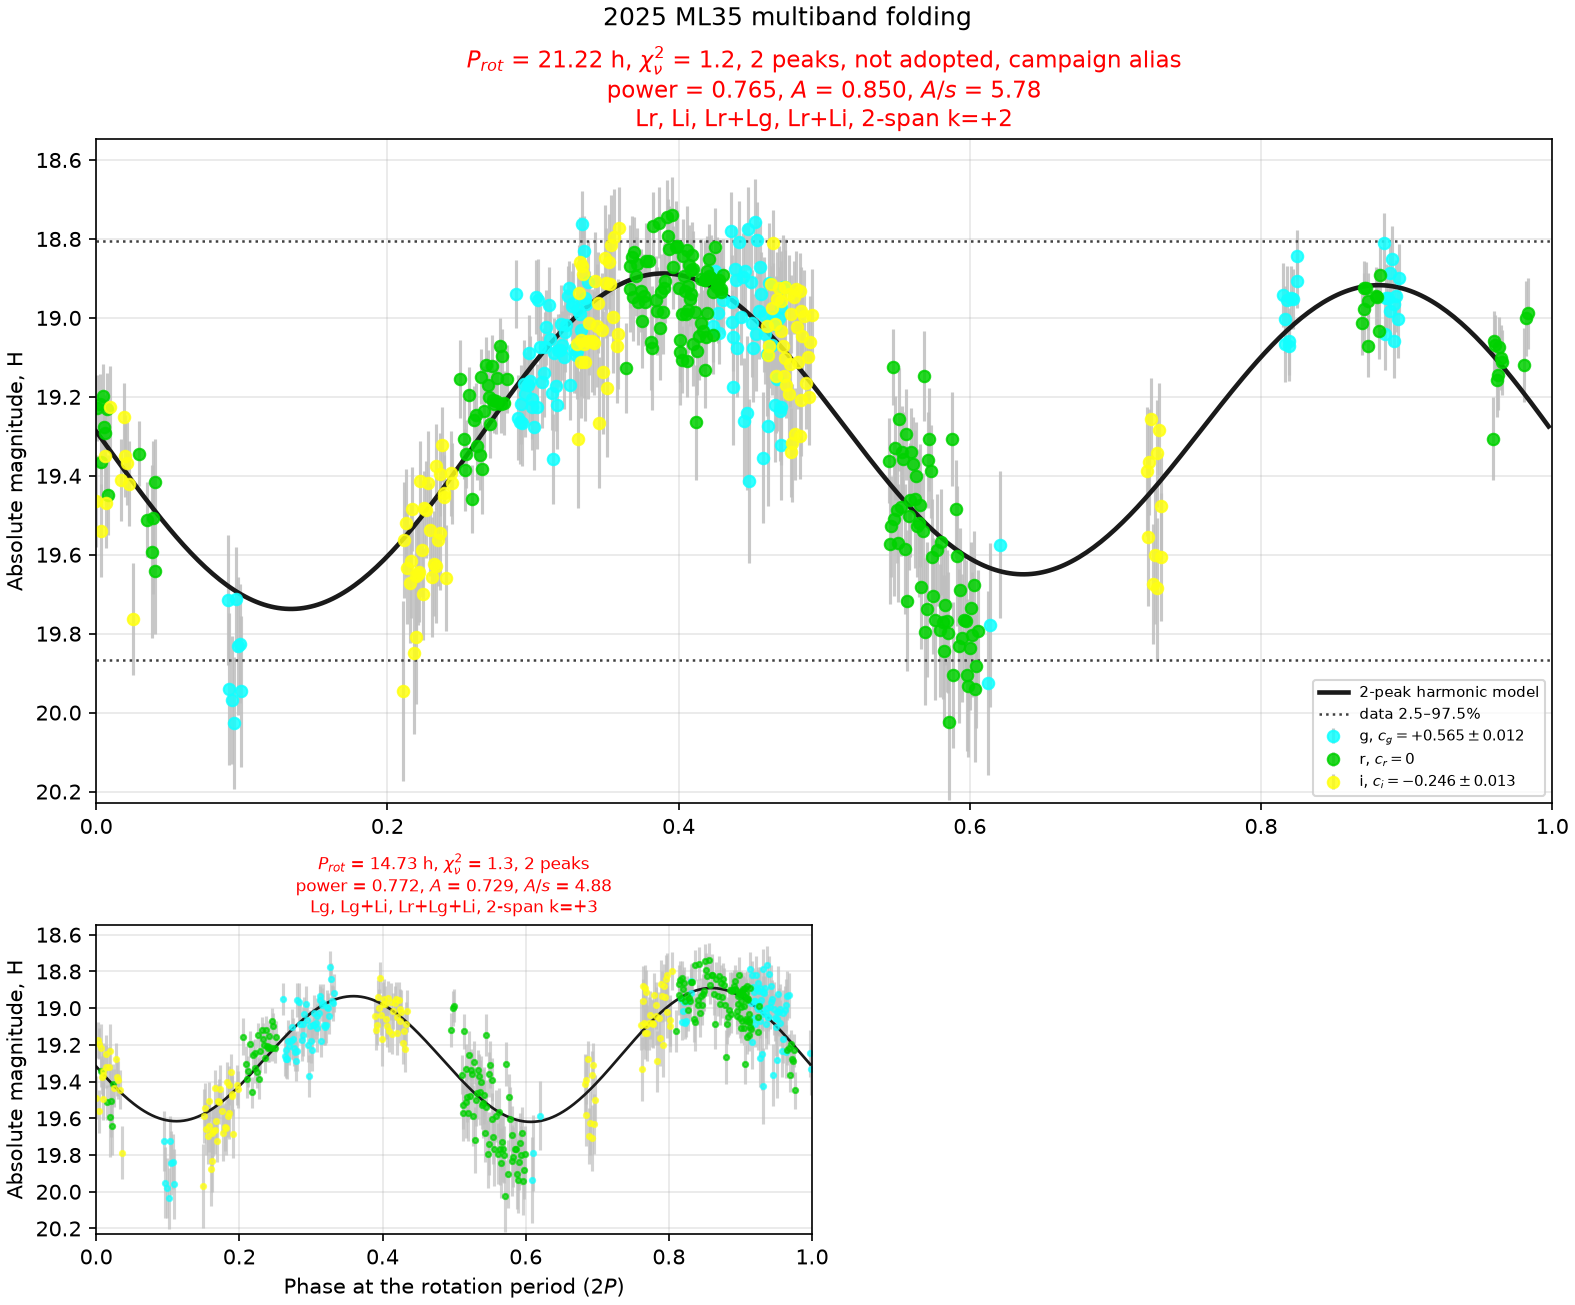

/Users/jzuluaga/dev/MVROC/code/figures/2025_ML35_multiband_folding.png
Data amplitude, 97.5% minus 2.5% = 1.061 mag


In [109]:
others = [
    item for item in two_peaks
    if item is not best and any(not str(lab).startswith(("span", "2-span")) for lab in item["labels"])
]
n_other = len(others)
nrow_other = int(np.ceil(n_other / 2.0)) if n_other else 0
fig = plt.figure(figsize=(10.5, 5.8 + 2.9 * nrow_other), layout="constrained")
if n_other == 0:
    ax_best = fig.add_subplot(1, 1, 1)
    other_axes = []
else:
    gs = fig.add_gridspec(1 + nrow_other, 2, height_ratios=[2.15] + [1.0] * nrow_other)
    ax_best = fig.add_subplot(gs[0, :])
    other_axes = [
        fig.add_subplot(gs[1 + i // 2, i % 2], sharex=ax_best, sharey=ax_best)
        for i in range(n_other)
    ]

phase = np.mod((t_fit - t0_fit) * best["f_rot"], 1.0)
beta_of = dict(zip(best["names"], best["beta"]))
err_of = dict(zip(best["names"], np.sqrt(np.clip(np.diag(best["cov"]), 0.0, None))))
for filt in present:
    sel = f_fit == filt
    if filt == ref:
        filt_label = rf"{filt}, $c_{{{filt}}} = 0$"
    else:
        filt_label = (
            rf"{filt}, $c_{{{filt}}} = {float(beta_of[f'c_{filt}']):+.3f}"
            rf" \pm {float(err_of[f'c_{filt}']):.3f}$"
        )
    ax_best.errorbar(
        phase[sel], best["y_on_ref"][sel], yerr=s_fit[sel],
        fmt="o", ms=5.5, alpha=0.85, color=BAND_COLOR.get(filt, "k"),
        ecolor="0.75", label=filt_label,
    )
ax_best.plot(best["phase_grid"], best["y_model"], color="0.1", lw=2.2, label="2-peak harmonic model")
bright, faint = np.percentile(best["y_on_ref"], [2.5, 97.5])
ax_best.axhline(bright, color="0.25", ls=":", lw=1.2, label="data 2.5–97.5%")
ax_best.axhline(faint, color="0.25", ls=":", lw=1.2)
status = "selected" if adopted else "not adopted, campaign alias"
ax_best.set_title(
    rf"$P_{{rot}}$ = {best['p_rot_h']:.2f} h, $\chi^2_\nu$ = {best['chi2_nu']:.1f}, "
    f"{best['n_peaks']} peaks, {status}\n"
    rf"power = {best['power']:.3f}, $A$ = {best['amp']:.3f}, $A/s$ = {best['amp_ratio']:.2f}"
    "\n" + ", ".join(best["labels"]),
    fontsize=11,
    color="red" if best["span_alias"] else "black",
)
ax_best.set_xlim(0, 1)
ax_best.grid(True, alpha=0.3)
ax_best.set_ylabel("Absolute magnitude, H")
ax_best.legend(loc="best", fontsize=7)

for ax, item in zip(other_axes, others):
    phase_i = np.mod((t_fit - t0_fit) * item["f_rot"], 1.0)
    beta_i = dict(zip(item["names"], item["beta"]))
    err_i = dict(zip(item["names"], np.sqrt(np.clip(np.diag(item["cov"]), 0.0, None))))
    for filt in present:
        sel = f_fit == filt
        if filt == ref:
            filt_label = rf"{filt}, $c_{{{filt}}} = 0$"
        else:
            filt_label = (
                rf"{filt}, $c_{{{filt}}} = {float(beta_i[f'c_{filt}']):+.3f}"
                rf" \pm {float(err_i[f'c_{filt}']):.3f}$"
            )
        ax.errorbar(
            phase_i[sel], item["y_on_ref"][sel], yerr=s_fit[sel],
            fmt="o", ms=2.5, alpha=0.7, color=BAND_COLOR.get(filt, "k"),
            ecolor="0.75", label=filt_label,
        )
    ax.plot(item["phase_grid"], item["y_model"], color="0.1", lw=1.3, label="2-peak harmonic model")
    ax.set_title(
        rf"$P_{{rot}}$ = {item['p_rot_h']:.2f} h, $\chi^2_\nu$ = {item['chi2_nu']:.1f}, "
        f"{item['n_peaks']} peaks\n"
        rf"power = {item['power']:.3f}, $A$ = {item['amp']:.3f}, $A/s$ = {item['amp_ratio']:.2f}"
        "\n" + ", ".join(item["labels"]),
        fontsize=8,
        color="red" if item["span_alias"] else "black",
    )
    ax.grid(True, alpha=0.3)

photometry = np.concatenate([np.asarray(item["y_on_ref"], dtype=float) for item in [best, *others]])
photometry = photometry[np.isfinite(photometry)]
bright_y = float(np.min(photometry))
faint_y = float(np.max(photometry))
pad = max(0.05, 0.15 * max(faint_y - bright_y, 0.05))
ax_best.set_ylim(faint_y + pad, bright_y - pad)
if n_other == 0:
    ax_best.set_xlabel("Phase at the rotation period ($2P$)")
else:
    for i, ax in enumerate(other_axes):
        if i % 2 == 0:
            ax.set_ylabel("Absolute magnitude, H")
        else:
            ax.tick_params(labelleft=False)
        if i // 2 == nrow_other - 1 or i + 2 >= n_other:
            ax.set_xlabel("Phase at the rotation period ($2P$)")
fig.suptitle(f"{PROVID} multiband folding", fontsize=12)
folding_path = FIG_DIR / f"{ASTEROID}_multiband_folding.png"
fig.savefig(folding_path, dpi=150)
plt.close(fig)
display(Image(filename=str(folding_path)))
print(folding_path)
print(f"Data amplitude, 97.5% minus 2.5% = {faint - bright:.3f} mag")

### Color indices

The zero points of the adopted model are the colors. The reference filter has zero point 0. The filters are ordered by wavelength as \(u\), \(g\), \(r\), \(i\), \(z\), \(y\). Every pair among the filters that have a zero point is a color, with the bluer filter first. With \(g\), \(r\), and \(i\) the colors are \(g-r\), \(g-i\), and \(r-i\).

A color is the difference of two zero points, so both filters are compared at the same rotational phase. With \(r\) as the reference, \(g-r\) is the zero point of \(g\), \(r-i\) is minus the zero point of \(i\), and \(g-i\) is the zero point of \(g\) minus the zero point of \(i\).

When both zero points are free, the uncertainty uses their covariance. When one filter is the reference, the uncertainty is the formal error of the free coefficient.

The filter \(u\) is measured afterwards, as the weighted mean of \(H_u\) minus the reference curve. Points farther than five robust scales are clipped. Each color \(u\) minus another filter is that offset minus the other filter's zero point, and the two uncertainties are added in quadrature.

In [110]:
beta = best["beta"]
names = best["names"]
cov = best["cov"]
color = {ref: 0.0}
sig_color = {ref: 0.0}
err_diag = np.sqrt(np.clip(np.diag(cov), 0.0, None))
for name, value, err in zip(names, beta, err_diag):
    if name.startswith("c_"):
        color[name[2:]] = float(value)
        sig_color[name[2:]] = float(err)

order = ("u", "g", "r", "i", "z", "y")
joint = [filt for filt in order if filt != "u" and filt in color]
computed = {}
for ia, a in enumerate(joint):
    for b in joint[ia + 1:]:
        value = float(color[a] - color[b])
        name_a = None if a == ref else f"c_{a}"
        name_b = None if b == ref else f"c_{b}"
        if name_a in names and name_b in names:
            i = names.index(name_a)
            j = names.index(name_b)
            var = cov[i, i] + cov[j, j] - 2.0 * cov[i, j]
            err = float(np.sqrt(max(var, 0.0)))
        elif name_a in names:
            err = float(sig_color[a])
        elif name_b in names:
            err = float(sig_color[b])
        else:
            err = float(np.sqrt(sig_color.get(a, 0.0) ** 2 + sig_color.get(b, 0.0) ** 2))
        computed[f"{a}-{b}"] = value
        computed[f"{a}-{b}_err"] = err

df_u = df_obj.dropna(subset=["H", "band"]).copy()
df_u["filt"] = df_u["band"].map(lambda b: alias.get(b, b))
df_u = df_u[df_u["filt"] == "u"]
if len(df_u) >= 2:
    rms_u = pd.to_numeric(df_u["rmsmag"], errors="coerce").to_numpy(float)
    t_u = df_u["t_days"].to_numpy(float)
    y_u = df_u["H"].to_numpy(float)
    s_u = np.where(np.isfinite(rms_u) & (rms_u > 0), rms_u, 0.01)
    ph_u = 2.0 * np.pi * best["f_rot"] * t_u
    cols_u = [np.zeros(len(t_u)) for filt in present if filt != ref]
    cols_u.append(np.ones(len(t_u)))
    for k in range(1, K_HARMONIC + 1):
        cols_u.append(np.sin(k * ph_u))
        cols_u.append(np.cos(k * ph_u))
    d_u = y_u - np.column_stack(cols_u) @ beta
    good = np.ones(len(d_u), dtype=bool)
    c_u = 0.0
    for _ in range(30):
        if int(good.sum()) < 2:
            break
        scale = 1.4826 * np.median(np.abs(d_u[good] - np.median(d_u[good])))
        w = 1.0 / np.maximum(s_u, 1e-4) ** 2
        c_u = float(np.sum(w[good] * d_u[good]) / np.sum(w[good]))
        new = np.abs(d_u - c_u) < 5.0 * max(scale, np.median(s_u))
        if np.array_equal(new, good):
            break
        good = new
    if int(good.sum()) >= 2:
        w = 1.0 / np.maximum(s_u, 1e-4) ** 2
        c_u = float(np.sum(w[good] * d_u[good]) / np.sum(w[good]))
        chi2_red = float(np.sum(((d_u[good] - c_u) / s_u[good]) ** 2) / max(int(good.sum()) - 1, 1))
        err_u = float(np.sqrt(1.0 / np.sum(w[good]) * max(chi2_red, 1.0)))
        for filt in joint:
            computed[f"u-{filt}"] = c_u - color[filt]
            computed[f"u-{filt}_err"] = float(np.sqrt(err_u ** 2 + sig_color.get(filt, 0.0) ** 2))

colors = {}
for ia, a in enumerate(order):
    for b in order[ia + 1:]:
        key = f"{a}-{b}"
        if key in computed:
            colors[key] = computed[key]
            colors[key + "_err"] = computed[key + "_err"]

print(f"Reference filter {ref}, period {best['p_rot_h']:.2f} h")
used = [
    filt for filt in order
    if any(
        (not key.endswith("_err")) and (key.startswith(f"{filt}-") or key.endswith(f"-{filt}"))
        for key in computed
    )
]
print("Filters with a zero point:", ", ".join(used))
if colors:
    show = pd.DataFrame({
        "mag": [colors[key] for key in colors if not key.endswith("_err")],
        "err": [colors[key + "_err"] for key in colors if not key.endswith("_err")],
    }, index=[key for key in colors if not key.endswith("_err")])
    display(show.round(3))
else:
    print("No color pair has both filters.")
for key in colors:
    if key.endswith("_err"):
        continue
    print(f"{key} = {colors[key]:+.3f} ± {colors[key + '_err']:.3f}")

Reference filter r, period 21.22 h
Filters with a zero point: g, r, i


,mag,err
g-r,0.565,0.012
g-i,0.811,0.015
r-i,0.246,0.013


g-r = +0.565 ± 0.012
g-i = +0.811 ± 0.015
r-i = +0.246 ± 0.013
